# Escalabilidade do tempo com o número de gerações — por seed
Mesma análise do notebook anterior, mas sem agregar entre seeds: cada seed tem sua própria curva (média das 3 repetições) e sua própria reta de referência ligando os extremos (32 e 2048 gerações).

## 1. Imports

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


## 2. Dados e agregações (pandas)

In [8]:
CAMINHO_CSV = "../PythonCode/Outputs/results.csv"
N_CORES = 1

df = pd.read_csv(CAMINHO_CSV)
print("Formato:", df.shape)
display(df.head())

# Checagens básicas
contagem = df.groupby(["n_cores", "seed"]).size()
print("Repetições por par (n_cores, seed):", sorted(contagem.unique()))
print("Valores faltantes:", int(df.isna().sum().sum()))

# Colunas de tempo ordenadas pelo número de gerações
colunas_tempo = sorted(
    [c for c in df.columns if c.startswith("time_")],
    key=lambda c: int(c.split("_")[1]),
)

df_nc = df[df["n_cores"] == N_CORES]
assert len(df_nc) > 0, f"Nenhuma linha com n_cores == {N_CORES}"
print(f"\nLinhas com n_cores == {N_CORES}:", len(df_nc))

# Média das repetições dentro de cada seed (uma linha por seed)
medias_por_seed = df_nc.groupby("seed")[colunas_tempo].mean()
medias_por_seed.columns = [int(c.split("_")[1]) for c in medias_por_seed.columns]
medias_por_seed.columns.name = "n_gens"

display(medias_por_seed)


Formato: (75, 9)


,n_cores,seed,time_32_gen,time_64_gen,time_128_gen,time_256_gen,time_512_gen,time_1024_gen,time_2048_gen
0,1,4,43.053089,109.172627,261.788561,583.238489,1100.646439,2015.593947,3655.688589
1,1,4,43.275543,109.881091,262.925391,586.156081,1106.762622,2026.014179,3670.477950
2,1,4,42.944421,109.081151,261.657032,582.752661,1101.131244,2016.606922,3636.929797
3,2,4,23.378426,57.251122,137.759463,307.250374,580.691928,1062.958702,1928.137151
4,2,4,23.489738,58.209185,138.125194,306.061575,576.511741,1053.639430,1909.765799


Repetições por par (n_cores, seed): [np.int64(3)]
Valores faltantes: 0

Linhas com n_cores == 1: 15


n_gens,32,64,128,256,512,1024,2048
seed,,,,,,,
0,32.453728,91.694093,220.918726,477.755241,1004.927174,1947.835044,3487.711046
1,76.407404,197.577507,503.822993,1093.691158,2347.286977,4490.014309,7361.141052
2,76.117823,178.389968,388.046642,863.620134,1756.745245,3361.126145,5977.119055
3,52.205007,121.580216,273.284243,556.274910,1077.647245,2019.841375,3771.697875
4,43.091017,109.378290,262.123661,584.049077,1102.846768,2019.405016,3654.365445


## 3. Conversão para numpy, retas de referência e gráficos

In [9]:
seeds = medias_por_seed.index.to_numpy()
gens = medias_por_seed.columns.to_numpy(dtype=float)
T = medias_por_seed.to_numpy()          # formato (n_seeds, n_gens)

# Reta de referência de cada seed, ligando seus próprios extremos (32 e 2048 gerações)
reta = T[:, [0]] + (T[:, [-1]] - T[:, [0]]) * (gens - gens[0]) / (gens[-1] - gens[0])

# Resíduo percentual com sinal: positivo = real acima da reta; negativo = abaixo
residuo_pct = (T - reta) / T * 100

# Tabela de resíduos (%) por seed
print("Resíduo (%) por seed e número de gerações")
print(f"{'seed':>5} " + " ".join(f"{int(g):>8}" for g in gens))
for s, linha in zip(seeds, residuo_pct):
    print(f"{s:>5} " + " ".join(f"{v:8.2f}" for v in linha))


Resíduo (%) por seed e número de gerações
 seed       32       64      128      256      512     1024     2048
    0     0.00     4.79    10.83    12.85    14.91    11.05     0.00
    1     0.00     2.80    15.98    19.01    22.85    18.46     0.00
    2     0.00     4.82     7.97    15.27    15.69    11.35     0.00
    3     0.00     8.50    16.09    16.32    12.98     6.80     0.00
    4     0.00     8.20    17.96    23.92    18.13     9.87     0.00


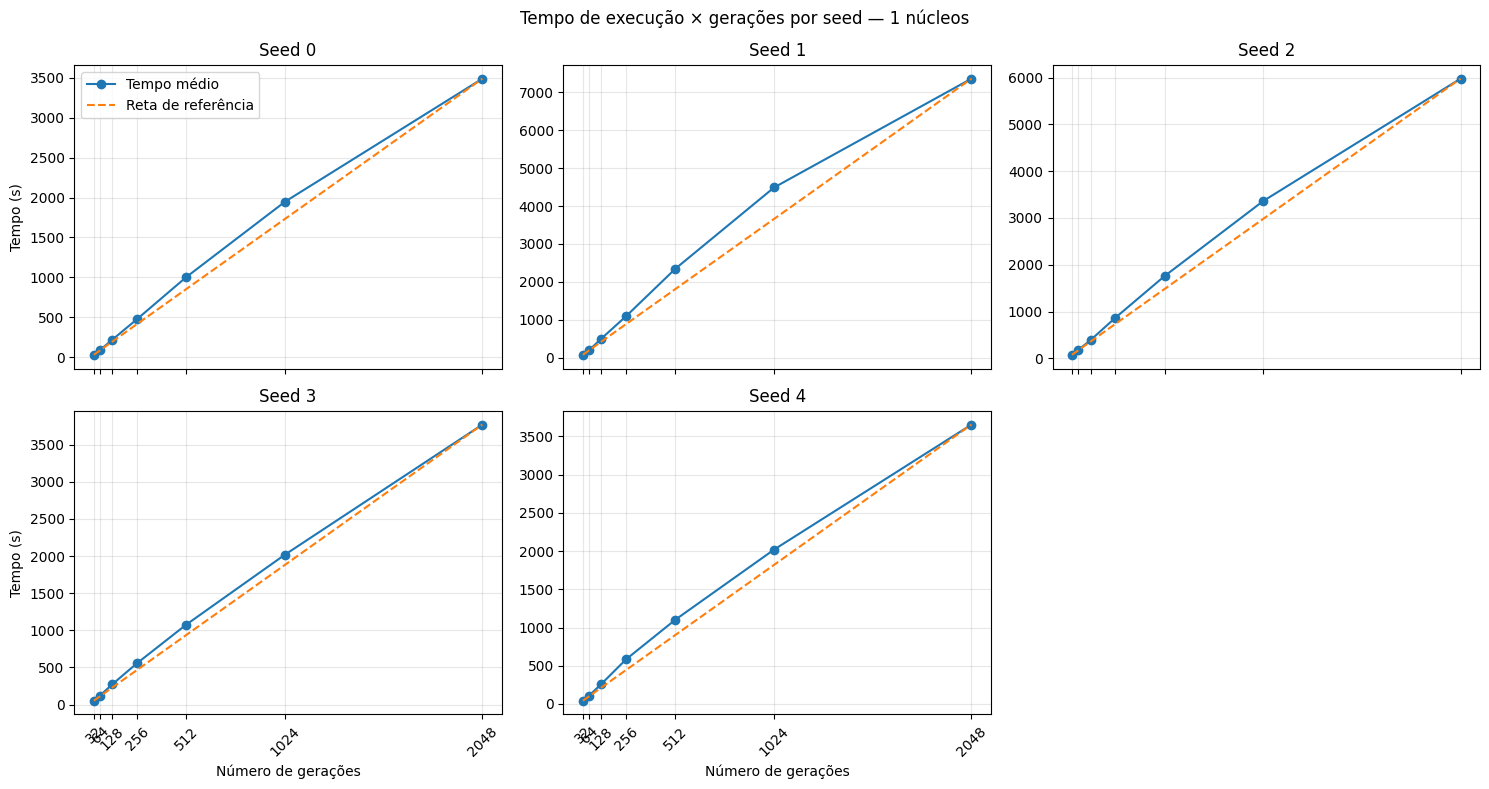

In [10]:
# Gráfico 1: tempo × gerações, um painel por seed, com a reta de referência de cada uma
n = len(seeds)
ncols = 3
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows), sharex=True)
axes = np.atleast_1d(axes).ravel()

for i, s in enumerate(seeds):
    ax = axes[i]
    ax.plot(gens, T[i], "o-", label="Tempo médio")
    ax.plot(gens, reta[i], "--", label="Reta de referência")
    ax.set_title(f"Seed {s}")
    ax.set_xticks(gens)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.3)
    if i % ncols == 0:
        ax.set_ylabel("Tempo (s)")
    if i // ncols == nrows - 1:
        ax.set_xlabel("Número de gerações")
    if i == 0:
        ax.legend()

for ax in axes[n:]:
    ax.set_visible(False)

fig.suptitle(f"Tempo de execução × gerações por seed — {N_CORES} núcleos")
fig.tight_layout()
plt.show()


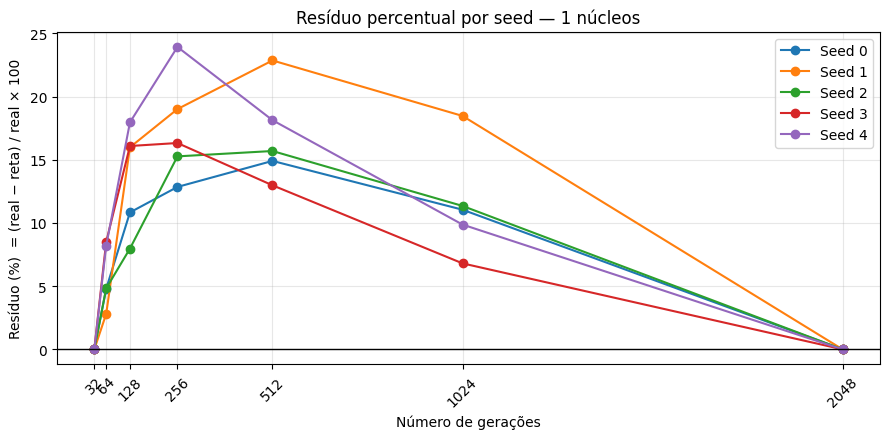

In [11]:
# Gráfico 2: resíduo percentual de todas as seeds no mesmo eixo
fig, ax = plt.subplots(figsize=(9, 4.5))
for i, s in enumerate(seeds):
    ax.plot(gens, residuo_pct[i], "o-", label=f"Seed {s}")
ax.axhline(0, color="black", linewidth=1)
ax.set_xlabel("Número de gerações")
ax.set_ylabel("Resíduo (%)  = (real − reta) / real × 100")
ax.set_title(f"Resíduo percentual por seed — {N_CORES} núcleos")
ax.set_xticks(gens)
ax.tick_params(axis="x", rotation=45)
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()


## 4. Inclinação por trecho (ΔT/Δn)
Inclinação entre pontos consecutivos, por seed e na média. Não depende da reta de referência.

,Seed 0,Seed 1,Seed 2,Seed 3,Seed 4,Média
trecho (gerações),,,,,,
32→64,1.8513,3.7866,3.1960,2.1680,2.0715,2.6147
64→128,2.0191,4.7851,3.2759,2.3704,2.3866,2.9674
128→256,2.0065,4.6083,3.7154,2.2109,2.5150,3.0112
256→512,2.0593,4.8969,3.4888,2.0366,2.0266,2.9016
512→1024,1.8416,4.1850,3.1336,1.8402,1.7902,2.5581
1024→2048,1.5038,2.8038,2.5547,1.7108,1.5966,2.0339


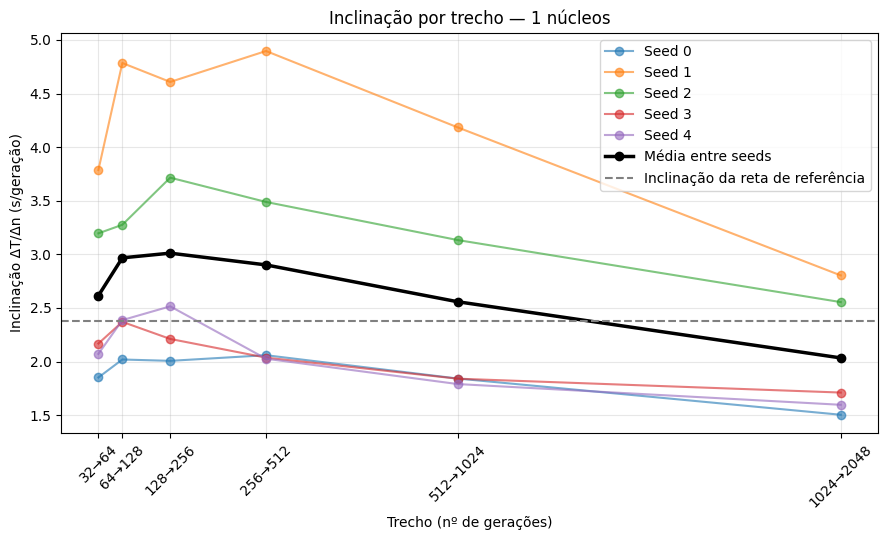

In [12]:
gens_int = np.array(
    [float(c) if not isinstance(c, str) else float(c.split("_")[1]) for c in medias_por_seed.columns]
)
T = medias_por_seed.to_numpy()          # (n_seeds, n_gens)
seeds = medias_por_seed.index.to_numpy()

# Inclinação de cada trecho entre pontos consecutivos (s/geração)
inclinacao = np.diff(T, axis=1) / np.diff(gens_int)        # (n_seeds, n_trechos)
trechos = [f"{int(a)}→{int(b)}" for a, b in zip(gens_int[:-1], gens_int[1:])]
ponto_medio = (gens_int[:-1] + gens_int[1:]) / 2

cols_seed = [f"Seed {s}" for s in seeds]
tab_incl = pd.DataFrame(inclinacao.T, index=trechos, columns=cols_seed)
tab_incl["Média"] = tab_incl[cols_seed].mean(axis=1)

tab_incl.index.name = "trecho (gerações)"
display(tab_incl.round(4))

# Gráfico: inclinação de cada trecho, por seed e na média
fig, ax = plt.subplots(figsize=(9, 5.5))
for i, s in enumerate(seeds):
    ax.plot(ponto_medio, inclinacao[i], "o-", alpha=0.6, label=f"Seed {s}")
ax.plot(ponto_medio, inclinacao.mean(axis=0), "ko-", linewidth=2.5, label="Média entre seeds")

tempo_medio = T.mean(axis=0)
incl_reta = (tempo_medio[-1] - tempo_medio[0]) / (gens_int[-1] - gens_int[0])
ax.axhline(incl_reta, color="gray", linestyle="--", label="Inclinação da reta de referência")

ax.set_xticks(ponto_medio)
ax.set_xticklabels(trechos, rotation=45)
ax.set_xlabel("Trecho (nº de gerações)")
ax.set_ylabel("Inclinação ΔT/Δn (s/geração)")
ax.set_title(f"Inclinação por trecho — {N_CORES} núcleos")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()